In [17]:
from pathlib import Path
import os, sys, random, warnings, subprocess, importlib.util
SEED = 42
random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

In [18]:
!pip install -r requirements.txt

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import torch
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, f1_score, classification_report, confusion_matrix, roc_auc_score, average_precision_score, roc_curve, precision_recall_curve

In [28]:
from sklearn.inspection import permutation_importance
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DATA_ROOT = Path("D:\Projects\AML_in_bitcoin\dataset")
print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| PyTorch', torch.__version__, '| device', DEVICE)
print('Dataset root:', DATA_ROOT.resolve())

Python 3.14.6 | pandas 3.0.6 | PyTorch 2.14.1+cpu | device cpu
Dataset root: D:\Projects\AML_in_bitcoin\dataset


<>:7: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
<>:7: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
C:\Users\Dell\AppData\Local\Temp\ipykernel_30316\2849968424.py:7: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
  DATA_ROOT = Path("D:\Projects\AML_in_bitcoin\dataset")


In [29]:
csv_files = list(DATA_ROOT.rglob("*.csv"))
print("Number of CSV files:", len(csv_files))

Number of CSV files: 9


In [30]:
for file in csv_files:
    print(file.name)

AddrAddr_edgelist.csv
AddrTx_edgelist.csv
TxAddr_edgelist.csv
txs_classes.csv
txs_edgelist.csv
txs_features.csv
wallets_classes.csv
wallets_features.csv
wallets_features_classes_combined.csv


In [31]:
def locate_file(root, filename):
    if not root.exists():
        return None
    matches = list(root.rglob(filename))
    return matches[0] if matches else None

In [32]:
feature_path = locate_file(DATA_ROOT, 'txs_features.csv')
class_path = locate_file(DATA_ROOT, 'txs_classes.csv')
edge_path = locate_file(DATA_ROOT, 'txs_edgelist.csv')

In [33]:
def read_csv_checked(path):
    with open(path, 'rb') as f:
        head = f.read(120)
    if b'git-lfs.github.com/spec/v1' in head:
        raise RuntimeError(f'{path} is a Git LFS pointer, not the dataset CSV. Use the official dataset download.')
    return pd.read_csv(path)


In [34]:
features_raw = read_csv_checked(feature_path)
classes_raw = read_csv_checked(class_path)
edges_raw = read_csv_checked(edge_path) if edge_path else None

print('Feature file:', feature_path, features_raw.shape)
print('Class file:', class_path, classes_raw.shape)
print('Edge file:', edge_path, None if edges_raw is None else edges_raw.shape)

display(features_raw.head(), classes_raw.head())

print('Feature columns:', list(features_raw.columns))
print('Class columns:', list(classes_raw.columns))

if edges_raw is not None:
    print('Edge columns:', list(edges_raw.columns))


Feature file: D:\Projects\AML_in_bitcoin\dataset\txs_features.csv (203769, 184)
Class file: D:\Projects\AML_in_bitcoin\dataset\txs_classes.csv (203769, 2)
Edge file: D:\Projects\AML_in_bitcoin\dataset\txs_edgelist.csv (234355, 2)


,txId,Time step,Local_feature_1,Local_feature_2,Local_feature_3,Local_feature_4,Local_feature_5,Local_feature_6,Local_feature_7,Local_feature_8,...,in_BTC_min,in_BTC_max,in_BTC_mean,in_BTC_median,in_BTC_total,out_BTC_min,out_BTC_max,out_BTC_mean,out_BTC_median,out_BTC_total
0,3321,1,-0.169615,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.160199,...,0.534072,0.534072,0.534072,0.534072,0.534072,1.668990e-01,0.367074,0.266986,0.266986,0.533972
1,11108,1,-0.137586,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.127429,...,5.611878,5.611878,5.611878,5.611878,5.611878,5.861940e-01,5.025584,2.805889,2.805889,5.611778
2,51816,1,-0.170103,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.160699,...,0.456608,0.456608,0.456608,0.456608,0.456608,2.279902e-01,0.228518,0.228254,0.228254,0.456508
3,68869,1,-0.114267,-0.184668,-1.201369,0.028105,-0.043875,-0.113002,0.547008,-0.161652,...,0.308900,8.000000,3.102967,1.000000,9.308900,1.229000e+00,8.079800,4.654400,4.654400,9.308800
4,89273,1,5.202107,-0.210553,-1.756361,-0.121970,260.090707,-0.113002,-0.061584,5.335864,...,852.164680,852.164680,852.164680,852.164680,852.164680,1.300000e-07,41.264036,0.065016,0.000441,852.164680


,txId,class
0,3321,3
1,11108,3
2,51816,3
3,68869,2
4,89273,2


Feature columns: ['txId', 'Time step', 'Local_feature_1', 'Local_feature_2', 'Local_feature_3', 'Local_feature_4', 'Local_feature_5', 'Local_feature_6', 'Local_feature_7', 'Local_feature_8', 'Local_feature_9', 'Local_feature_10', 'Local_feature_11', 'Local_feature_12', 'Local_feature_13', 'Local_feature_14', 'Local_feature_15', 'Local_feature_16', 'Local_feature_17', 'Local_feature_18', 'Local_feature_19', 'Local_feature_20', 'Local_feature_21', 'Local_feature_22', 'Local_feature_23', 'Local_feature_24', 'Local_feature_25', 'Local_feature_26', 'Local_feature_27', 'Local_feature_28', 'Local_feature_29', 'Local_feature_30', 'Local_feature_31', 'Local_feature_32', 'Local_feature_33', 'Local_feature_34', 'Local_feature_35', 'Local_feature_36', 'Local_feature_37', 'Local_feature_38', 'Local_feature_39', 'Local_feature_40', 'Local_feature_41', 'Local_feature_42', 'Local_feature_43', 'Local_feature_44', 'Local_feature_45', 'Local_feature_46', 'Local_feature_47', 'Local_feature_48', 'Local_fea

In [35]:
def find_col(df, candidates):
    def norm(value):
        return ''.join((ch for ch in str(value).strip().lower() if ch.isalnum()))
    low = {norm(c): c for c in df.columns}
    for name in candidates:
        if norm(name) in low:
            return low[norm(name)]
    return None


In [36]:
fid = find_col(features_raw, ['txId', 'tx_id', 'transaction_id', 'id'])
cid = find_col(classes_raw, ['txId', 'tx_id', 'transaction_id', 'id'])
label_col = find_col(classes_raw, ['class', 'label', 'labels'])

if label_col is None:
    raise ValueError(f'Cannot identify label column from {list(classes_raw.columns)}')

if fid and cid:
    if features_raw[fid].duplicated().any() or classes_raw[cid].duplicated().any():
        raise ValueError('Duplicate transaction IDs detected; resolve duplicate rows before supervised evaluation.')
    data = features_raw.merge(classes_raw[[cid, label_col]], left_on=fid, right_on=cid, how='inner', validate='one_to_one')
    if len(data) != len(features_raw) or len(data) != len(classes_raw):
        raise ValueError('Feature/class IDs do not align one-to-one; inspect unmatched IDs before proceeding.')
    txid_col = fid
else:
    if len(features_raw) != len(classes_raw):
        raise ValueError('No shared transaction ID found and row counts differ; safe alignment is impossible.')
    data = features_raw.copy()
    data[label_col] = classes_raw[label_col].to_numpy()
    txid_col = fid


In [37]:
def map_label(v):
    s = str(v).strip().lower()
    if s in {'1', '1.0', 'illicit', 'illegal', 'fraudulent'}:
        return 1
    if s in {'2', '2.0', 'licit', 'legal', 'legitimate'}:
        return 0
    if s in {'3', '3.0', 'unknown', 'unlabeled', 'unlabelled', 'nan', ''}:
        return np.nan
    return np.nan


In [38]:
data['_target'] = data[label_col].map(map_label)

unrecognized = sorted(set(data.loc[data['_target'].isna(), label_col].astype(str)))

print('Raw dimensions:', data.shape, '| mapped labels (NaN=unknown/unrecognized):')

display(data[label_col].value_counts(dropna=False).rename('count').to_frame())

if unrecognized:
    print('Excluded unknown/unrecognized raw labels:', unrecognized)

print('Duplicate full rows:', int(data.duplicated().sum()), '| duplicate IDs:', int(data[txid_col].duplicated().sum()) if txid_col else 'ID unavailable')
print('Missing cells:', int(data.isna().sum().sum()), '| infinite numeric cells:', int(np.isinf(data.select_dtypes(include=np.number)).sum().sum()))
print('Dtypes:')

display(data.dtypes.astype(str).value_counts().to_frame('columns'))
display(data.describe(include='all').T.head(30))


Raw dimensions: (203769, 186) | mapped labels (NaN=unknown/unrecognized):


C:\Users\Dell\AppData\Local\Temp\ipykernel_30316\2278190618.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data['_target'] = data[label_col].map(map_label)


,count
class,
3,157205
2,42019
1,4545


Excluded unknown/unrecognized raw labels: ['3']
Duplicate full rows: 0 | duplicate IDs: 0
Missing cells: 173610 | infinite numeric cells: 0
Dtypes:


,columns
float64,183
int64,3


,count,mean,std,min,25%,50%,75%,max
txId,203769.0,1.711310e+08,1.104655e+08,1076.000000,8.433452e+07,1.624375e+08,2.454798e+08,4.032446e+08
Time step,203769.0,2.384396e+01,1.517217e+01,1.000000,9.000000e+00,2.300000e+01,3.800000e+01,4.900000e+01
Local_feature_1,203769.0,2.231681e-17,1.000002e+00,-0.172983,-1.725317e-01,-1.692045e-01,-1.318553e-01,7.168197e+01
Local_feature_2,203769.0,1.785345e-17,1.000002e+00,-0.210553,-1.803266e-01,-1.328975e-01,-5.524241e-02,7.359505e+01
Local_feature_3,203769.0,3.570689e-17,1.000002e+00,-1.756361,-1.201369e+00,4.636092e-01,1.018602e+00,2.683580e+00
Local_feature_4,203769.0,6.792678e-17,1.000002e+00,-0.121970,-1.219696e-01,-1.219696e-01,-1.219696e-01,4.902760e+01
Local_feature_5,203769.0,7.531922e-17,1.000002e+00,-0.063725,-4.387455e-02,-4.387455e-02,-4.387455e-02,2.600907e+02
Local_feature_6,203769.0,6.081330e-17,1.000002e+00,-0.113002,-1.130020e-01,-1.130020e-01,-1.130020e-01,5.456518e+01
Local_feature_7,203769.0,2.678017e-17,1.000002e+00,-0.061584,-6.158379e-02,-6.158379e-02,-6.158379e-02,1.134409e+02
Local_feature_8,203769.0,3.347521e-17,1.000002e+00,-0.163646,-1.635168e-01,-1.620440e-01,-1.355932e-01,7.335457e+01


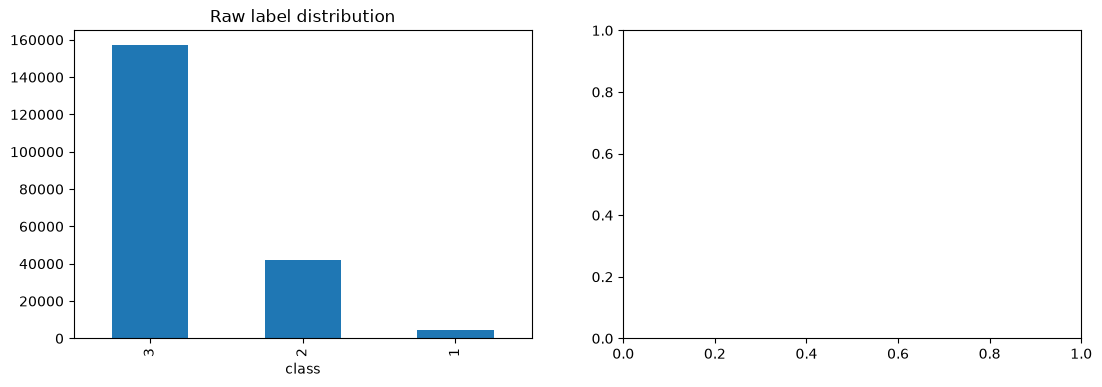

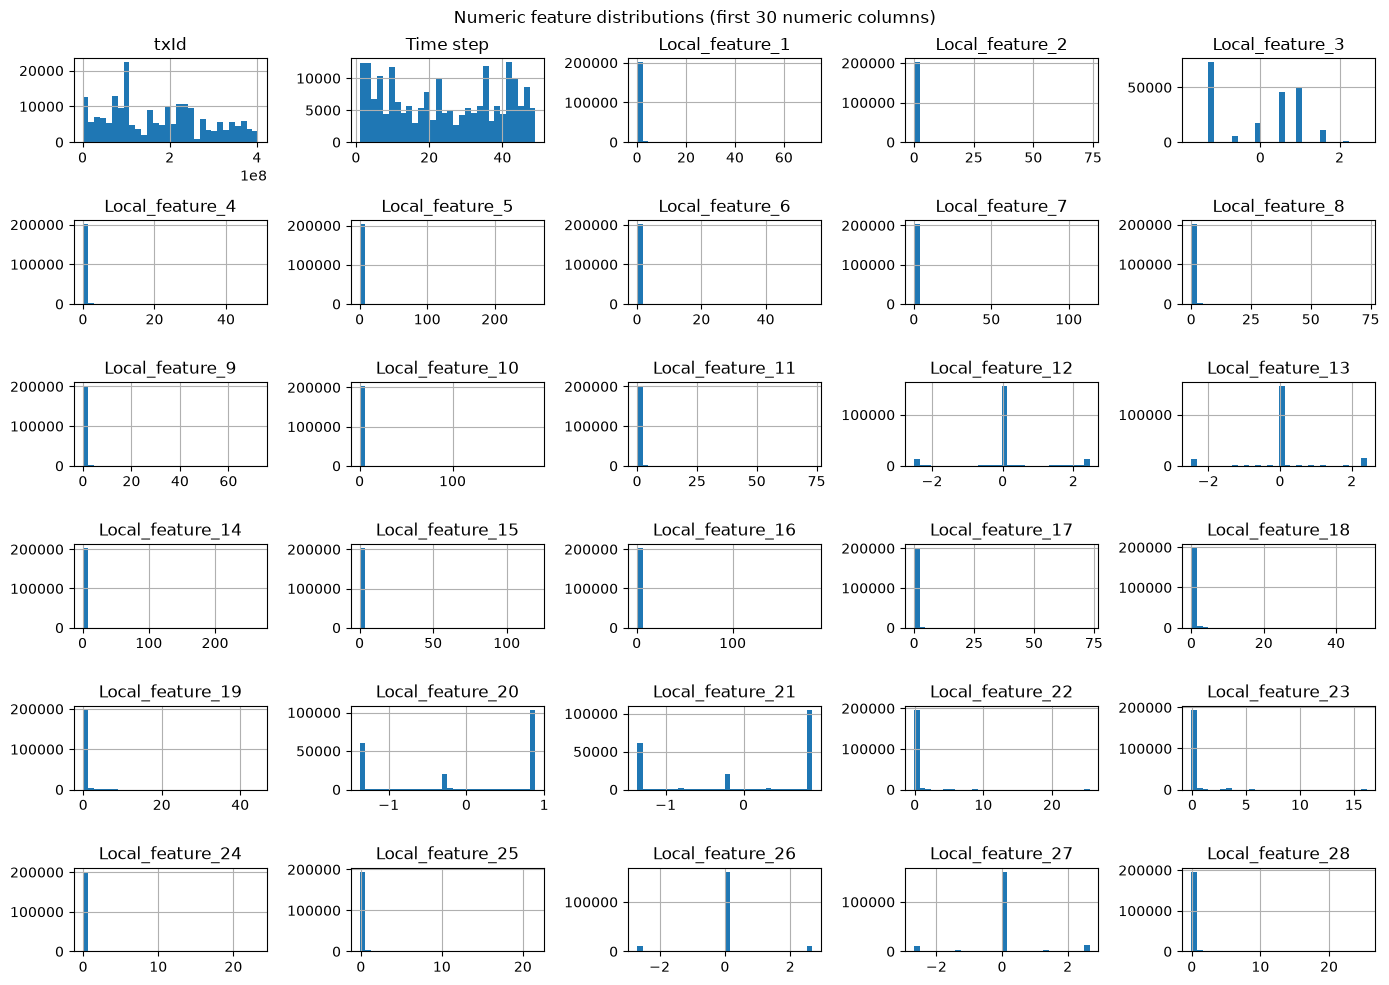

In [39]:
label_counts = data[label_col].value_counts(dropna=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
label_counts.plot.bar(ax=ax[0], title='Raw label distribution')
num = data.select_dtypes(include=np.number).replace([np.inf, -np.inf], np.nan)

if len(num.columns):
    num.iloc[:, :min(30, len(num.columns))].hist(figsize=(14, 10), bins=30)
    plt.suptitle('Numeric feature distributions (first 30 numeric columns)')
    plt.tight_layout()
    plt.show()


Most skewed numeric columns:


,skew
Local_feature_34,235.935705
Local_feature_37,222.670091
Local_feature_35,200.435594
Local_feature_36,148.300704
Local_feature_73,129.564567
Local_feature_14,129.067301
Local_feature_72,127.480130
Local_feature_5,122.457259
num_output_addresses,122.169977
Local_feature_71,110.789891


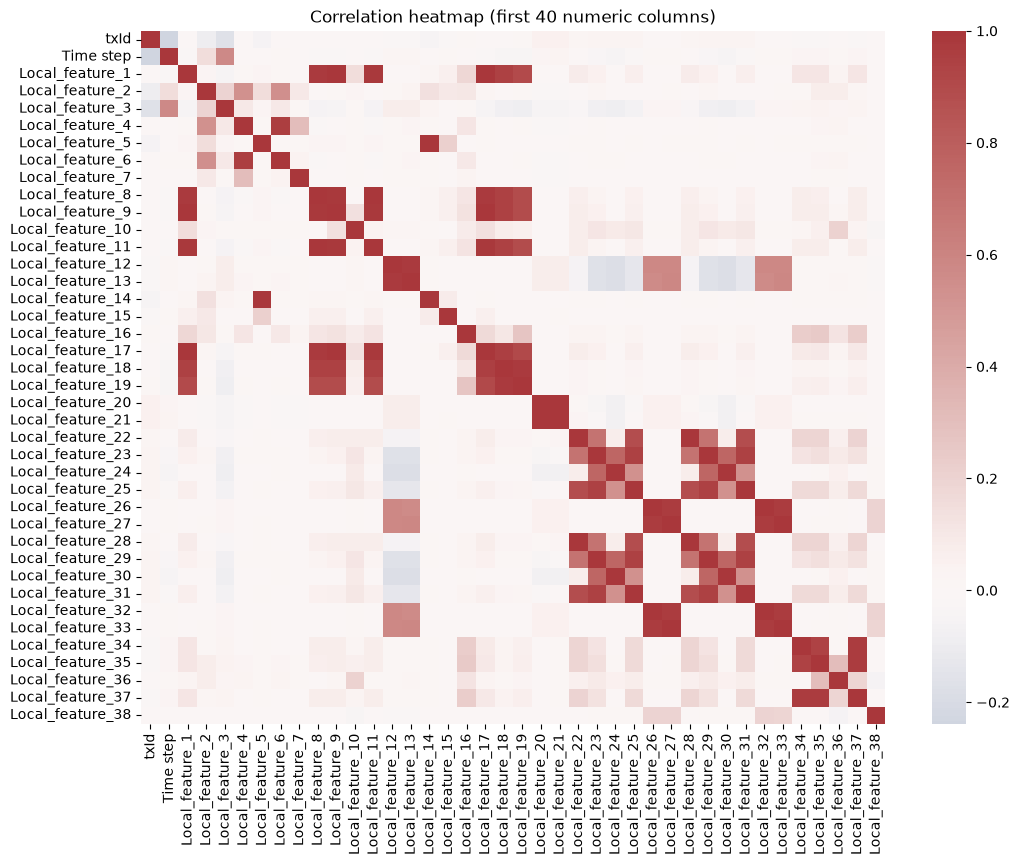

In [40]:
skew = num.skew(numeric_only=True).sort_values(key=lambda x: x.abs(), ascending=False)
print('Most skewed numeric columns:')
display(skew.head(15).to_frame('skew'))

if len(num.columns) > 1:
    corr = num.iloc[:, :min(40, len(num.columns))].corr()
    plt.figure(figsize=(12, 9))
    sns.heatmap(corr, cmap='vlag', center=0)
    plt.title('Correlation heatmap (first 40 numeric columns)')
    plt.show()


In [41]:
time_col = find_col(features_raw, ['time', 'timestamp', 'time_step', 'timestep'])
metadata_cols = {c for c in [fid, cid, label_col, '_target'] if c is not None}

if time_col:
    metadata_cols.add(time_col)

candidate_cols = [c for c in features_raw.columns if c not in {fid}]
Xraw = data[[c for c in candidate_cols if c in data.columns and c not in {cid, label_col, '_target'}]].copy()

In [42]:
numeric_cols = []
categorical_cols = []

for c in Xraw.columns:
    converted = pd.to_numeric(Xraw[c], errors='coerce')
    if pd.api.types.is_numeric_dtype(Xraw[c]) or converted.notna().mean() >= 0.95:
        Xraw[c] = converted
        numeric_cols.append(c)
    elif Xraw[c].nunique(dropna=True) <= 50:
        categorical_cols.append(c)
    else:
        print(f'Excluding high-cardinality nonnumeric column {c!r} (likely identifier/metadata).')

Xraw = Xraw[numeric_cols + categorical_cols]
known = data['_target'].notna()

In [43]:
X_known = Xraw.loc[known].reset_index(drop=True)
y = data.loc[known, '_target'].astype(int).to_numpy()
ids = data.loc[known, txid_col].reset_index(drop=True) if txid_col else pd.Series(np.arange(known.sum()), name='row_index')
times = pd.to_numeric(data.loc[known, time_col], errors='coerce').reset_index(drop=True) if time_col else None

print('Labeled rows:', len(y), '| licit=0:', int((y == 0).sum()), '| illicit=1:', int((y == 1).sum()))
print('Predictors:', len(X_known.columns), 'numeric:', len(numeric_cols), 'categorical:', len(categorical_cols), '| time:', time_col)

if X_known.columns.duplicated().any():
    raise ValueError('Duplicate feature column names must be resolved.')

if X_known.empty:
    raise ValueError('No usable feature columns remain after schema inspection.')

graph_feature_note = 'Graph features unavailable'

Labeled rows: 46564 | licit=0: 42019 | illicit=1: 4545
Predictors: 183 numeric: 183 categorical: 0 | time: Time step


In [44]:
if edges_raw is not None and time_col and txid_col:
    edge_cols = list(edges_raw.columns)
    src = find_col(edges_raw, ['txId1', 'source', 'src', 'from', 'tx1'])
    dst = find_col(edges_raw, ['txId2', 'target', 'destination', 'dst', 'to', 'tx2'])
    if src is None or dst is None:
        if len(edge_cols) >= 2:
            src, dst = edge_cols[:2]
    if src is not None and dst is not None:
        all_times = pd.to_numeric(data.set_index(txid_col)[time_col], errors='coerce')
        e = edges_raw[[src, dst]].rename(columns={src: 'src', dst: 'dst'}).copy()
        e['t_src'] = e.src.map(all_times)
        e['t_dst'] = e.dst.map(all_times)
        e = e.dropna(subset=['t_src', 't_dst'])
        e['event_time'] = e[['t_src', 't_dst']].max(axis=1)
        indeg = pd.Series(0.0, index=ids.astype(str))
        outdeg = indeg.copy()
        e = e.sort_values('event_time')
        edge_t = e.event_time.to_numpy()
        src_ids = e.src.astype(str).to_numpy()
        dst_ids = e.dst.astype(str).to_numpy()
        tx_times = times.to_numpy()
        tx_ids = ids.astype(str).to_numpy()
        gd_in = np.zeros(len(y), dtype=np.float32)
        gd_out = np.zeros(len(y), dtype=np.float32)
        src_count = {}
        dst_count = {}
        j = 0
        order = np.argsort(tx_times)
        for i in order:
            t = tx_times[i]
            while j < len(edge_t) and edge_t[j] <= t:
                s, d = (src_ids[j], dst_ids[j])
                src_count[s] = src_count.get(s, 0) + 1
                dst_count[d] = dst_count.get(d, 0) + 1
                j += 1
            gd_out[i] = src_count.get(tx_ids[i], 0)
            gd_in[i] = dst_count.get(tx_ids[i], 0)
        X_known['graph_in_degree_past_or_current'] = gd_in
        X_known['graph_out_degree_past_or_current'] = gd_out
        X_known['graph_total_degree_past_or_current'] = gd_in + gd_out
        graph_feature_note = 'Causal cumulative directed degrees from available transaction edges'
    else:
        graph_feature_note = 'Skipped: could not infer edge endpoint columns'
elif edges_raw is None:
    graph_feature_note = 'Skipped: txs_edgelist.csv not found'
elif not time_col:
    graph_feature_note = 'Skipped: no timestamp/time-step column; cannot guarantee causal graph features'
else:
    graph_feature_note = 'Skipped: transaction ID missing; cannot safely align graph edges'

C:\Users\Dell\AppData\Local\Temp\ipykernel_30316\2286521067.py:38: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_known['graph_in_degree_past_or_current'] = gd_in
C:\Users\Dell\AppData\Local\Temp\ipykernel_30316\2286521067.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_known['graph_out_degree_past_or_current'] = gd_out
C:\Users\Dell\AppData\Local\Temp\ipykernel_30316\2286521067.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor perf

In [45]:
print(graph_feature_note)

Causal cumulative directed degrees from available transaction edges


In [46]:
if times is not None and times.notna().all() and (times.nunique() >= 3):
    uniq = np.sort(times.unique())
    n1 = max(1, int(np.floor(0.7 * len(uniq))))
    n2 = max(n1 + 1, int(np.floor(0.85 * len(uniq))))
    train_t = set(uniq[:n1])
    val_t = set(uniq[n1:n2])
    test_t = set(uniq[n2:])
    tr = np.flatnonzero(times.isin(train_t))
    va = np.flatnonzero(times.isin(val_t))
    te = np.flatnonzero(times.isin(test_t))
    split_method = 'chronological by time step'
else:
    tr, rest = train_test_split(np.arange(len(y)), test_size=0.3, random_state=SEED, stratify=y)
    va, te = train_test_split(rest, test_size=0.5, random_state=SEED, stratify=y[rest])
    split_method = 'stratified random (timestamp unavailable/insufficient)'

In [47]:
if min(len(tr), len(va), len(te)) == 0:
    raise ValueError('A split is empty; inspect timestamps and labeled sample counts.')

print(split_method, '| sizes:', len(tr), len(va), len(te))
print('Time ranges:', [(times.iloc[ix].min(), times.iloc[ix].max()) if times is not None else None for ix in [tr, va, te]])
print('Class counts [licit, illicit]:', [np.bincount(y[ix], minlength=2).tolist() for ix in [tr, va, te]])
print('Exact feature-row overlap train/val/test:', len(set(map(tuple, X_known.iloc[tr].fillna('<NA>').astype(str).to_numpy())) & set(map(tuple, X_known.iloc[va].fillna('<NA>').astype(str).to_numpy()))), len(set(map(tuple, X_known.iloc[tr].fillna('<NA>').astype(str).to_numpy())) & set(map(tuple, X_known.iloc[te].fillna('<NA>').astype(str).to_numpy()))))

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_selection import VarianceThreshold
num_cols = X_known.select_dtypes(include=np.number).columns.tolist()

chronological by time step | sizes: 29894 7829 8841
Time ranges: [(np.int64(1), np.int64(34)), (np.int64(35), np.int64(41)), (np.int64(42), np.int64(49))]
Class counts [licit, illicit]: [[26432, 3462], [7154, 675], [8433, 408]]
Exact feature-row overlap train/val/test: 0 0


In [48]:
cat_cols = [c for c in X_known.columns if c not in num_cols]

try:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)

preprocessor = ColumnTransformer([('numeric', Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)), ('scale', StandardScaler())]), num_cols), ('categorical', Pipeline([('impute', SimpleImputer(strategy='most_frequent')), ('onehot', ohe)]), cat_cols)], remainder='drop', verbose_feature_names_out=False)
Xtr = preprocessor.fit_transform(X_known.iloc[tr])
Xva = preprocessor.transform(X_known.iloc[va])
Xte = preprocessor.transform(X_known.iloc[te])
selector = VarianceThreshold(0.0)
Xtr = selector.fit_transform(Xtr)
Xva = selector.transform(Xva)
Xte = selector.transform(Xte)

In [49]:
Xtr = np.nan_to_num(Xtr, nan=0, posinf=0, neginf=0).astype(np.float32)
Xva = np.nan_to_num(Xva, nan=0, posinf=0, neginf=0).astype(np.float32)
Xte = np.nan_to_num(Xte, nan=0, posinf=0, neginf=0).astype(np.float32)
ytr, yva, yte = (y[tr], y[va], y[te])
feature_names = np.asarray(preprocessor.get_feature_names_out())[selector.get_support()]

print('Processed dimensions:', Xtr.shape, Xva.shape, Xte.shape)
print('Outlier diagnostic: training numeric feature 1st/99th quantiles before scaling')

display(X_known.iloc[tr][num_cols].quantile([0.01, 0.5, 0.99]).T.head(20))

Processed dimensions: (29894, 203) (7829, 203) (8841, 203)
Outlier diagnostic: training numeric feature 1st/99th quantiles before scaling


,0.01,0.50,0.99
Time step,1.000000,15.000000,34.000000
Local_feature_1,-0.172977,-0.170459,1.292120
Local_feature_2,-0.195340,-0.158783,1.341617
Local_feature_3,-1.201369,-0.646376,1.573595
Local_feature_4,-0.121970,-0.046932,3.179681
Local_feature_5,-0.063725,-0.043875,0.453766
Local_feature_6,-0.113002,-0.029140,3.157625
Local_feature_7,-0.061584,-0.061584,0.851305
Local_feature_8,-0.163645,-0.163431,0.729528
Local_feature_9,-0.169455,-0.167399,1.100201


In [50]:
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

In [51]:
class MLP(nn.Module):

    def __init__(self, n_in, hidden=(50,), activation='relu', dropout=0.0, batch_norm=False):
        super().__init__()
        layers = []
        d = n_in
        act = nn.ReLU if activation.lower() == 'relu' else nn.GELU
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if batch_norm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(act())
            if dropout:
                layers.append(nn.Dropout(dropout))
            d = h
        layers.append(nn.Linear(d, 2))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

In [52]:
def train_model(config, max_epochs=200, patience=20):
    model = MLP(n_in=Xtr.shape[1], hidden=config['hidden'], activation=config['activation'], dropout=config['dropout'], batch_norm=config['batch_norm']).to(DEVICE)
    counts = np.bincount(ytr, minlength=2)
    weights = torch.tensor(len(ytr) / (2 * np.maximum(counts, 1)), dtype=torch.float32, device=DEVICE)
    criterion = nn.CrossEntropyLoss(weight=weights)
    opt_cls = torch.optim.AdamW if config.get('optimizer', 'adamw') == 'adamw' else torch.optim.Adam
    opt = opt_cls(model.parameters(), lr=config.get('lr', 0.001), weight_decay=config.get('weight_decay', 0.0001))
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='min', factor=0.5, patience=5)
    ds = TensorDataset(torch.from_numpy(Xtr), torch.from_numpy(ytr.astype(np.int64)))
    loader = DataLoader(ds, batch_size=min(config.get('batch_size', 1024), len(ds)), shuffle=True)
    xt = torch.from_numpy(Xva).to(DEVICE)
    yt = torch.from_numpy(yva.astype(np.int64)).to(DEVICE)
    history = {'train_loss': [], 'val_loss': []}
    best = float('inf')
    best_state = None
    stale = 0
    for epoch in range(max_epochs):
        model.train()
        losses = []
        for xb, yb in loader:
            xb, yb = (xb.to(DEVICE), yb.to(DEVICE))
            opt.zero_grad(set_to_none=True)
            loss = criterion(model(xb), yb)
            loss.backward()
            opt.step()
            losses.append(loss.item())
        model.eval()
        with torch.no_grad():
            vl = criterion(model(xt), yt).item()
        tl = float(np.mean(losses))
        history['train_loss'].append(tl)
        history['val_loss'].append(vl)
        sched.step(vl)
        if vl < best - 1e-05:
            best = vl
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            stale = 0
        else:
            stale += 1
        if stale >= patience:
            break
    model.load_state_dict(best_state)
    model.eval()
    return (model, history)


In [53]:
def probs(model, X):
    model.eval()
    with torch.no_grad():
        return torch.softmax(model(torch.from_numpy(X).to(DEVICE)), dim=1)[:, 1].cpu().numpy()

In [54]:
baseline_config = {'hidden': (50,), 'activation': 'relu', 'dropout': 0.0, 'batch_norm': False, 'optimizer': 'adam', 'lr': 0.001, 'weight_decay': 0.0, 'batch_size': 1024}

baseline_model, baseline_history = train_model(baseline_config, max_epochs=200, patience=200)

baseline_val_prob = probs(baseline_model, Xva)

baseline_val_f1 = f1_score(yva, baseline_val_prob >= 0.5, zero_division=0)

print('Baseline validation F1 at 0.5:', baseline_val_f1, 'epochs:', len(baseline_history['train_loss']))

candidates = [{'hidden': (256, 128, 64), 'activation': 'relu', 'dropout': 0.25, 'batch_norm': True, 'optimizer': 'adamw', 'lr': 0.001, 'weight_decay': 0.0001, 'batch_size': 1024}, {'hidden': (128, 64), 'activation': 'gelu', 'dropout': 0.2, 'batch_norm': True, 'optimizer': 'adamw', 'lr': 0.0005, 'weight_decay': 0.0005, 'batch_size': 1024}, {'hidden': (256, 128), 'activation': 'relu', 'dropout': 0.35, 'batch_norm': False, 'optimizer': 'adamw', 'lr': 0.0005, 'weight_decay': 0.001, 'batch_size': 1024}]

trial_rows = []

models = []

histories = []

for i, cfg in enumerate(candidates, 1):
    model, hist = train_model(cfg, max_epochs=200, patience=20)
    pv = probs(model, Xva)
    score = f1_score(yva, pv >= 0.5, zero_division=0)
    trial_rows.append({'trial': i, 'config': str(cfg), 'val_f1@0.5': score, 'epochs': len(hist['train_loss'])})
    models.append(model)
    histories.append(hist)


Baseline validation F1 at 0.5: 0.43885971492873216 epochs: 200


In [55]:
tuning_results = pd.DataFrame(trial_rows).sort_values('val_f1@0.5', ascending=False)

display(tuning_results)

best_idx = int(tuning_results.iloc[0].trial) - 1

optimized_model = models[best_idx]

optimized_history = histories[best_idx]

optimized_config = candidates[best_idx]

val_prob = probs(optimized_model, Xva)

thresholds = np.unique(np.r_[np.linspace(0.01, 0.99, 199), val_prob])

threshold_f1 = np.array([f1_score(yva, val_prob >= t, zero_division=0) for t in thresholds])

best_threshold = float(thresholds[np.argmax(threshold_f1)])

print('Selected configuration:', optimized_config)

print('Frozen validation threshold:', best_threshold, 'validation illicit F1:', float(threshold_f1.max()))


,trial,config,val_f1@0.5,epochs
1,2,"{'hidden': (128, 64), 'activation': 'gelu', 'd...",0.538426,27
0,1,"{'hidden': (256, 128, 64), 'activation': 'relu...",0.504288,23
2,3,"{'hidden': (256, 128), 'activation': 'relu', '...",0.425225,22


Selected configuration: {'hidden': (128, 64), 'activation': 'gelu', 'dropout': 0.2, 'batch_norm': True, 'optimizer': 'adamw', 'lr': 0.0005, 'weight_decay': 0.0005, 'batch_size': 1024}
Frozen validation threshold: 0.8501144647598267 validation illicit F1: 0.6829971181556196


In [56]:
graph_cols = [c for c in X_known.columns if c.startswith('graph_')]

ablation_rows = []

if graph_cols:
    base_cols = [c for c in X_known.columns if c not in graph_cols]
    pp0 = ColumnTransformer([('numeric', Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)), ('scale', StandardScaler())]), [c for c in base_cols if c in X_known.select_dtypes(include=np.number).columns]), ('categorical', Pipeline([('impute', SimpleImputer(strategy='most_frequent')), ('onehot', ohe)]), [c for c in base_cols if c in cat_cols])], remainder='drop', verbose_feature_names_out=False)
    a_tr = pp0.fit_transform(X_known.iloc[tr][base_cols])
    a_va = pp0.transform(X_known.iloc[va][base_cols])
    sel0 = VarianceThreshold(0.0)
    a_tr = sel0.fit_transform(a_tr).astype(np.float32)
    a_va = sel0.transform(a_va).astype(np.float32)
    full_tr, full_va = (Xtr, Xva)
    Xtr, Xva = (a_tr, a_va)
    ab_model, ab_hist = train_model(optimized_config, max_epochs=200, patience=20)
    ab_f1 = f1_score(yva, probs(ab_model, Xva) >= 0.5, zero_division=0)
    Xtr, Xva = (full_tr, full_va)
    ablation_rows = [{'feature_set': 'original cleaned/transformed', 'validation F1 @ 0.5': ab_f1}, {'feature_set': 'original + causal graph degrees', 'validation F1 @ 0.5': f1_score(yva, val_prob >= 0.5, zero_division=0)}]
else:
    ablation_rows = [{'feature_set': 'original cleaned/transformed', 'validation F1 @ 0.5': baseline_val_f1}, {'feature_set': 'graph engineered features', 'validation F1 @ 0.5': np.nan}]


In [57]:
ablation = pd.DataFrame(ablation_rows)

display(ablation)

test_prob = probs(optimized_model, Xte)

test_pred = (test_prob >= best_threshold).astype(int)

metrics = {'Accuracy': accuracy_score(yte, test_pred), 'Illicit precision': precision_score(yte, test_pred, zero_division=0), 'Illicit recall': recall_score(yte, test_pred, zero_division=0), 'Illicit F1': f1_score(yte, test_pred, zero_division=0), 'Macro F1': f1_score(yte, test_pred, average='macro', zero_division=0), 'Weighted F1': f1_score(yte, test_pred, average='weighted', zero_division=0)}

if len(np.unique(yte)) == 2:
    metrics['ROC-AUC'] = roc_auc_score(yte, test_prob)
    metrics['PR-AUC (average precision)'] = average_precision_score(yte, test_prob)

print('TEST metrics (threshold frozen from validation):')

display(pd.Series(metrics).to_frame('score'))

print(classification_report(yte, test_pred, labels=[0, 1], target_names=['licit', 'illicit'], zero_division=0))

print('Confusion matrix [licit, illicit]:\n', confusion_matrix(yte, test_pred, labels=[0, 1]))


,feature_set,validation F1 @ 0.5
0,original cleaned/transformed,0.545021
1,original + causal graph degrees,0.538426


TEST metrics (threshold frozen from validation):


,score
Accuracy,0.961430
Illicit precision,0.616725
Illicit recall,0.433824
Illicit F1,0.509353
Macro F1,0.744639
Weighted F1,0.958210
ROC-AUC,0.793437
PR-AUC (average precision),0.439998


              precision    recall  f1-score   support

       licit       0.97      0.99      0.98      8433
     illicit       0.62      0.43      0.51       408

    accuracy                           0.96      8841
   macro avg       0.79      0.71      0.74      8841
weighted avg       0.96      0.96      0.96      8841

Confusion matrix [licit, illicit]:
 [[8323  110]
 [ 231  177]]


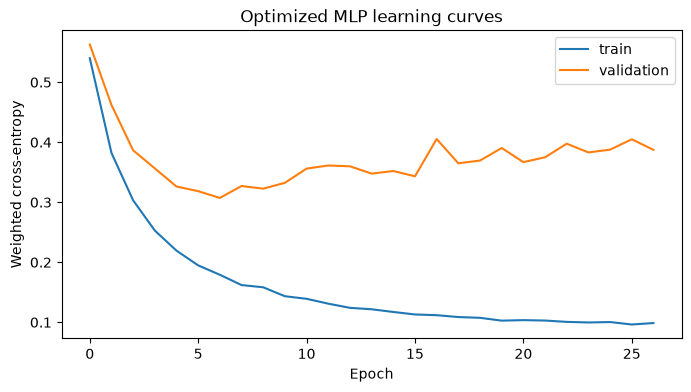

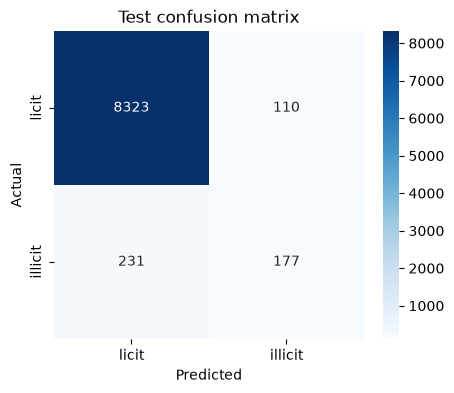

In [58]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(optimized_history['train_loss'], label='train')

ax.plot(optimized_history['val_loss'], label='validation')

ax.set(xlabel='Epoch', ylabel='Weighted cross-entropy', title='Optimized MLP learning curves')

ax.legend()

plt.show()

cm = confusion_matrix(yte, test_pred, labels=[0, 1])

plt.figure(figsize=(5, 4))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['licit', 'illicit'], yticklabels=['licit', 'illicit'])

plt.xlabel('Predicted')

plt.ylabel('Actual')

plt.title('Test confusion matrix')

plt.show()


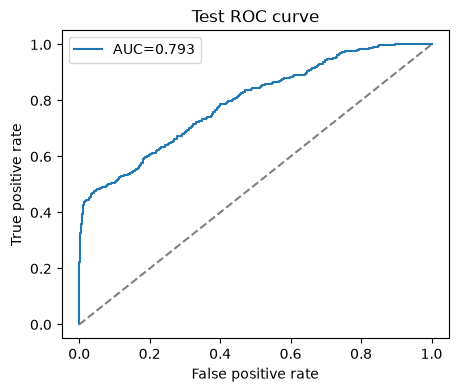

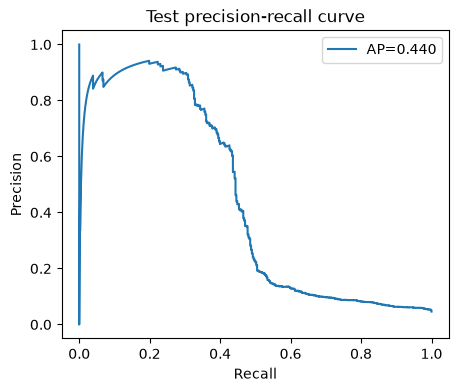

In [59]:
if len(np.unique(yte)) == 2:
    fpr, tpr, _ = roc_curve(yte, test_prob)
    plt.figure(figsize=(5, 4))
    plt.plot(fpr, tpr, label=f'AUC={roc_auc_score(yte, test_prob):.3f}')
    plt.plot([0, 1], [0, 1], '--', color='gray')
    plt.xlabel('False positive rate')
    plt.ylabel('True positive rate')
    plt.title('Test ROC curve')
    plt.legend()
    plt.show()
    pr, rc, _ = precision_recall_curve(yte, test_prob)
    plt.figure(figsize=(5, 4))
    plt.plot(rc, pr, label=f'AP={average_precision_score(yte, test_prob):.3f}')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Test precision-recall curve')
    plt.legend()
    plt.show()


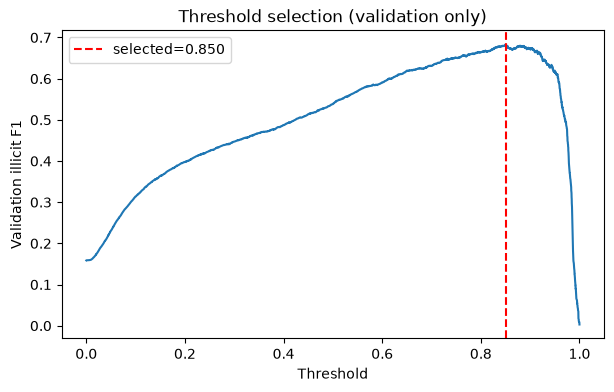

In [60]:
plt.figure(figsize=(7, 4))

plt.plot(thresholds, threshold_f1)

plt.axvline(best_threshold, color='red', ls='--', label=f'selected={best_threshold:.3f}')

plt.xlabel('Threshold')

plt.ylabel('Validation illicit F1')

plt.title('Threshold selection (validation only)')

plt.legend()

plt.show()


,feature,validation F1 drop
0,Local_feature_53,0.101803
1,Local_feature_55,0.099871
2,Local_feature_52,0.089689
3,Aggregate_feature_49,0.083850
4,Aggregate_feature_51,0.083380
5,Local_feature_81,0.078813
6,Aggregate_feature_14,0.066028
7,Local_feature_80,0.056926
8,Aggregate_feature_55,0.051918
9,Local_feature_75,0.046361


Text(0.5, 1.0, 'Validation permutation importance (F1 decrease)')

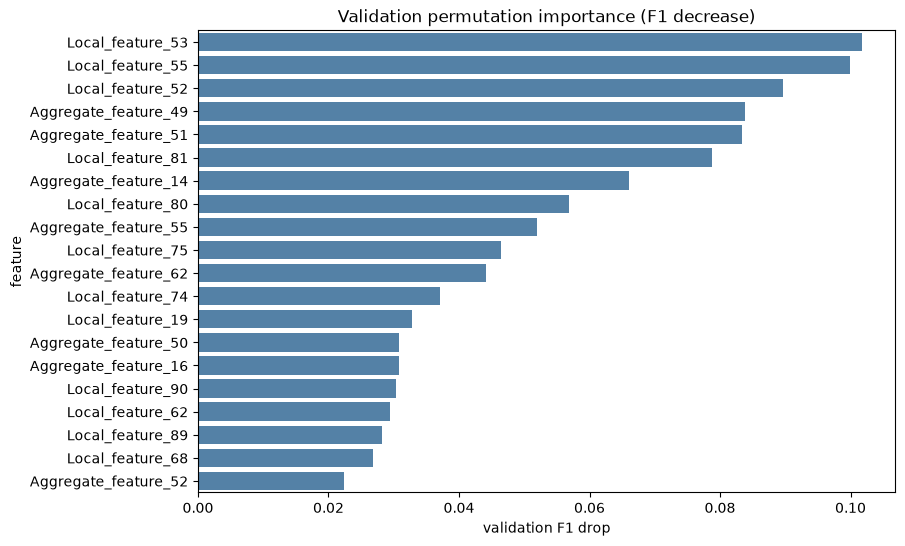

In [61]:
rng = np.random.default_rng(SEED)

baseline_v = f1_score(yva, probs(optimized_model, Xva) >= best_threshold, zero_division=0)

imp = []

for j in range(Xva.shape[1]):
    drops = []
    for _ in range(3):
        xp = Xva.copy()
        xp[:, j] = xp[rng.permutation(len(xp)), j]
        drops.append(baseline_v - f1_score(yva, probs(optimized_model, xp) >= best_threshold, zero_division=0))
    imp.append(float(np.mean(drops)))

top = np.argsort(imp)[-20:][::-1]

importance = pd.DataFrame({'feature': feature_names[top], 'validation F1 drop': np.array(imp)[top]})

display(importance)

plt.figure(figsize=(9, 6))

sns.barplot(data=importance, y='feature', x='validation F1 drop', color='steelblue')

plt.title('Validation permutation importance (F1 decrease)')


In [62]:
plt.tight_layout()

plt.show()

EXPECTED_COLUMNS = list(X_known.columns)


<Figure size 640x480 with 0 Axes>

In [63]:
def predict_transactions(input_features, transaction_ids=None):
    """Return transaction ID, licit/illicit probabilities, predicted class, and frozen threshold.
    input_features: DataFrame with the original feature columns (extra columns are ignored).
    """
    if not isinstance(input_features, pd.DataFrame):
        raise TypeError('input_features must be a pandas DataFrame with named columns.')
    missing = set(EXPECTED_COLUMNS) - set(input_features.columns)
    if missing:
        raise ValueError(f'Missing required feature columns: {sorted(missing)}')
    frame = input_features[EXPECTED_COLUMNS].copy()
    transformed = selector.transform(preprocessor.transform(frame))
    transformed = np.nan_to_num(transformed, nan=0, posinf=0, neginf=0).astype(np.float32)
    p = probs(optimized_model, transformed)
    if transaction_ids is None:
        if txid_col and txid_col in input_features.columns:
            transaction_ids = input_features[txid_col].to_numpy()
        else:
            transaction_ids = np.arange(len(frame))
    if len(transaction_ids) != len(frame):
        raise ValueError('transaction_ids length must match input row count.')
    return pd.DataFrame({'transaction_id': transaction_ids, 'p_licit': 1 - p, 'p_illicit': p, 'predicted_label': np.where(p >= best_threshold, 'illicit', 'licit'), 'threshold': best_threshold})


In [64]:
from sklearn.metrics import accuracy_score, f1_score

# Get illicit probabilities for the held-out test set
test_prob = probs(optimized_model, Xte)

# Use the threshold selected from validation data
test_pred = (test_prob >= best_threshold).astype(int)

accuracy = accuracy_score(yte, test_pred)
illicit_f1 = f1_score(yte, test_pred, pos_label=1, zero_division=0)

print(f"Test accuracy: {accuracy:.4f}")
print(f"Test illicit-class F1: {illicit_f1:.4f}")

Test accuracy: 0.9614
Test illicit-class F1: 0.5094
